# Assignment 5: Topic modeling and sentiment around the 2026 US midterms
Executed capstone notebook. It loads the results that `build_report.py` built by running the full pipeline on the cached real data, and walks through every exhibit in order. To recompute, call `run_pipeline()` from `src.pipeline`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from src.pipeline import load_results
from src import table_generator as tg
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
R = load_results()
R.params

{'start': '2026-03-02',
 'end': '2026-10-09',
 'k': 30,
 'lags': 'bic',
 'cov': 'HC1',
 'high_quantile': 0.8,
 'n_tweets': 5816,
 'built': '2026-10-10T12:24:19.340326-04:00'}

## 1. Data
Coverage of every source, the tweet filter waterfall and the prediction-market consensus.

In [2]:
display(R.pm.coverage)
display(R.filter_report)
display(R.market.alignment.T)
R.pm.consensus.tail()

chamber,House,Senate,Sweep
venue,,,
kalshi,155,155,155
polymarket,155,155,155
predictit,64,64,0


,step,remaining,removed
0,raw,5882,0
1,duplicate ids,5882,0
2,non-English,5882,0
3,retweets,5882,0
4,followers < 10,5882,0
5,views < 100,5816,66
6,"astroturf (same text, >= 5 accounts)",5816,0
7,fewer than 4 tokens,5816,0


,AAPL,ENPH,GOOGL,ICLN,ITA,ITB,JPM,LMT,META,MSFT,NVDA,SPY,UNH,XAR,XHB,XLE,XLF,XLK,XLV,XOM,^VIX,DGS2,DGS3MO
missing_days,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
forward_filled,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0


,House,Senate,Sweep
2026-10-05,0.919835,0.650000,0.641583
2026-10-06,0.914258,0.641807,0.632825
2026-10-07,0.905421,0.636856,0.628951
2026-10-08,0.902800,0.628207,0.621435
2026-10-09,0.902750,0.618157,0.609556


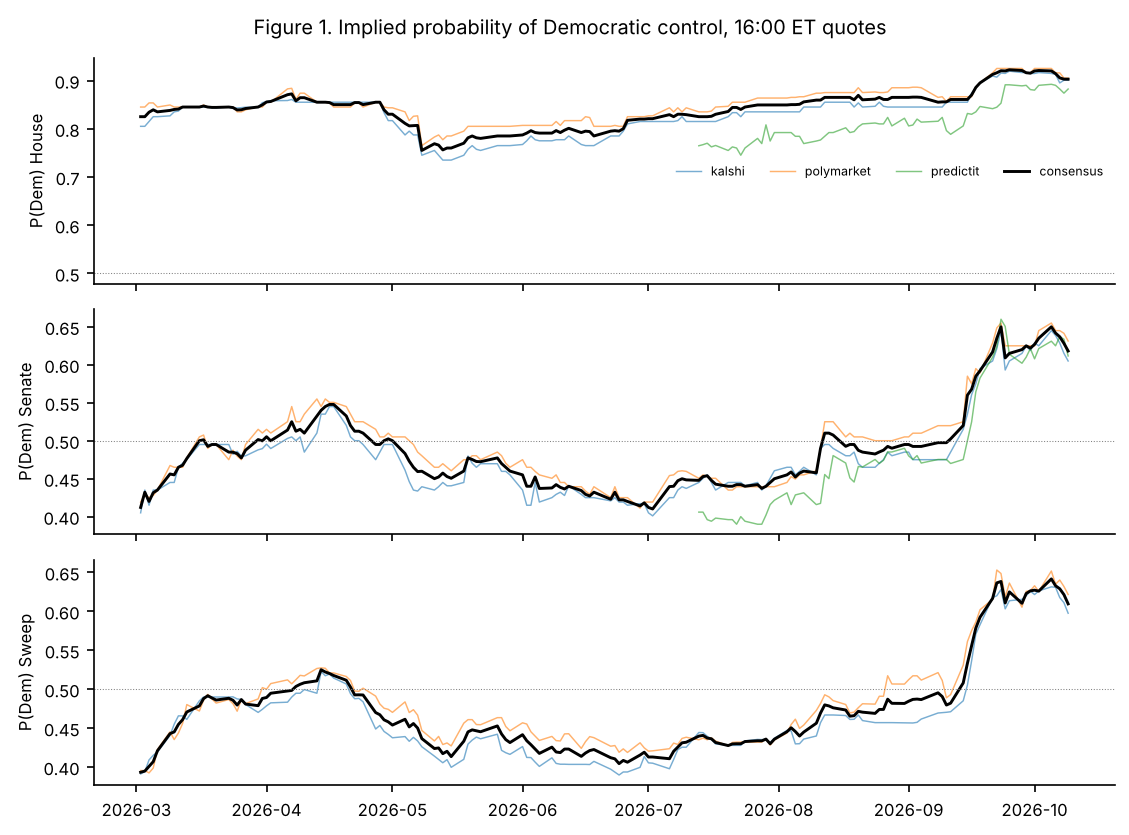

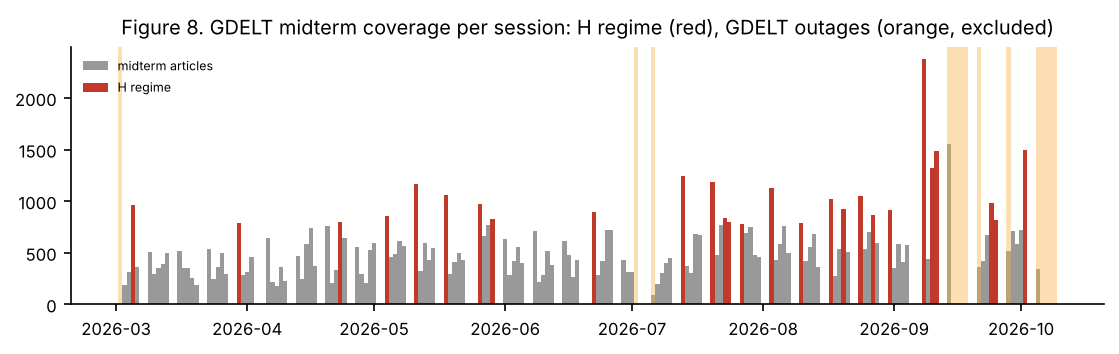

In [3]:
display(Image('outputs/figures/fig1_prediction_markets.png'))
display(Image('outputs/figures/fig8_gdelt_regimes.png'))

## 2. LSA topics
Uncentred TF-IDF, truncated SVD (k = 30), varimax rotation. Table 1A lists each labelled pole with its top term loadings.

| Issue | Axis | σ | Seed share | Purity | Stability | Top terms (loading) |
|---|---|---|---|---|---|---|
| Economy/Inflation | 23+ | 3.07 | 0.71 | 0.97 | 1.00 | tariffs (0.73); trump's (0.17); trump's tariffs (0.13); trade (0.13); trump tariffs (0.12); canada (0.11) |
| Economy/Inflation | 6+ | 4.06 | 0.74 | 0.93 | 1.00 | gas (0.48); prices (0.39); gas prices (0.29); grocery (0.19); groceries (0.17); grocery prices (0.15) |
| Energy/Climate | 21+ | 3.11 | 0.48 | 0.86 | 0.60 | energy (0.50); climate (0.15); ballot (0.14); bills (0.13); costs (0.11); energy costs (0.10) |
| Foreign Policy/Defense | 3+ | 4.63 | 0.79 | 0.94 | 1.00 | war (0.52); iran (0.46); war iran (0.24); iran war (0.18); military (0.17); billion (0.09) |
| General | 0+ | 9.79 | 0.07 | 0.36 | – | trump (0.19); republicans (0.19); health (0.16); democrats (0.15); congress (0.13); people (0.13) |
| Healthcare | 10+ | 3.65 | 0.79 | 0.97 | 1.00 | care (0.59); health care (0.53); health (0.30); affordable (0.11); care costs (0.09); affordable care (0.08) |
| Healthcare | 10- | 3.65 | 0.23 | 0.71 | 1.00 | healthcare (0.12); insurance (0.09); health insurance (0.08); house (0.07); america (0.05); housing (0.03) |
| Healthcare | 20+ | 3.13 | 0.31 | 0.90 | 1.00 | medicare (0.43); social security (0.37); security (0.37); social (0.35); security medicare (0.20); medicare medicaid (0.14) |
| Healthcare | 5+ | 4.09 | 0.72 | 0.99 | 1.00 | health insurance (0.56); insurance (0.55); health (0.45); insurance premiums (0.08); insurance companies (0.07); insurance costs (0.06) |
| Healthcare | 8+ | 3.77 | 0.41 | 0.94 | 1.00 | medicaid (0.48); cuts (0.39); cut (0.18); medicaid cuts (0.16); big (0.16); tax cuts (0.15) |
| Healthcare | 9+ | 3.71 | 0.55 | 0.71 | 1.00 | healthcare (0.55); premiums (0.30); obamacare (0.20); costs (0.19); healthcare costs (0.14); medicare (0.12) |
| Healthcare Affordability | 12+ | 3.50 | 0.25 | 0.73 | 1.00 | obamacare (0.40); money (0.29); insurance companies (0.15); companies (0.14); pay (0.14); dollars (0.13) |
| Healthcare Affordability | 26+ | 2.98 | 0.66 | 0.93 | 1.00 | aca (0.46); subsidies (0.41); aca subsidies (0.31); expire (0.17); coverage (0.15); let (0.14) |
| Healthcare Affordability | 7+ | 3.88 | 0.68 | 0.65 | 1.00 | drug (0.48); drug prices (0.42); prices (0.36); prescription (0.29); prescription drug (0.27); lower (0.16) |
| Housing Affordability | 15+ | 3.38 | 0.50 | 0.93 | 1.00 | rent (0.54); rent control (0.35); ballot (0.32); control (0.31); massachusetts (0.15); groceries (0.13) |
| Housing Affordability | 2+ | 4.71 | 0.60 | 0.99 | 1.00 | housing (0.54); housing costs (0.37); costs (0.36); lower (0.20); lower housing (0.20); bipartisan (0.12) |
| Immigration | 17+ | 3.27 | 0.69 | 0.99 | 1.00 | immigration (0.61); illegal (0.28); enforcement (0.27); immigration enforcement (0.22); illegal immigration (0.16); immigrants (0.11) |
| Immigration | 4+ | 4.46 | 0.64 | 0.99 | 1.00 | border (0.54); ice (0.31); border patrol (0.29); patrol (0.28); ice border (0.22); fund (0.14) |

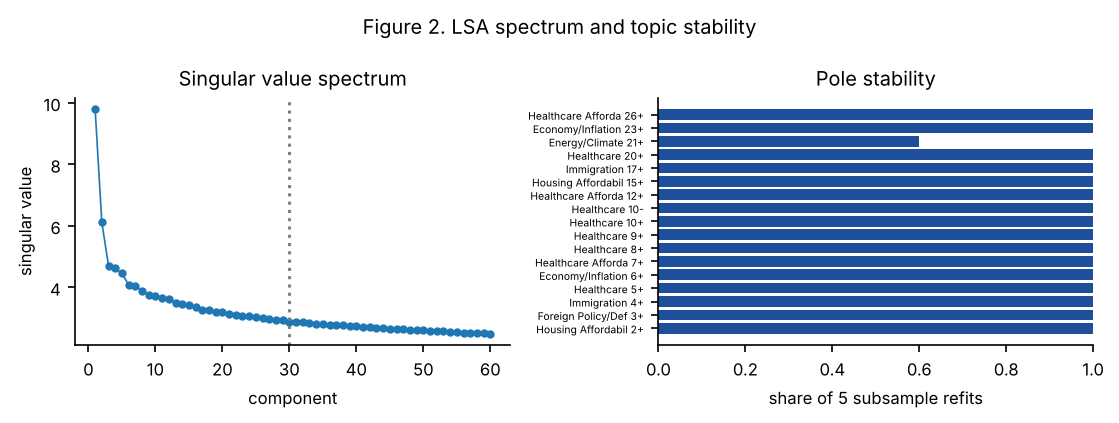

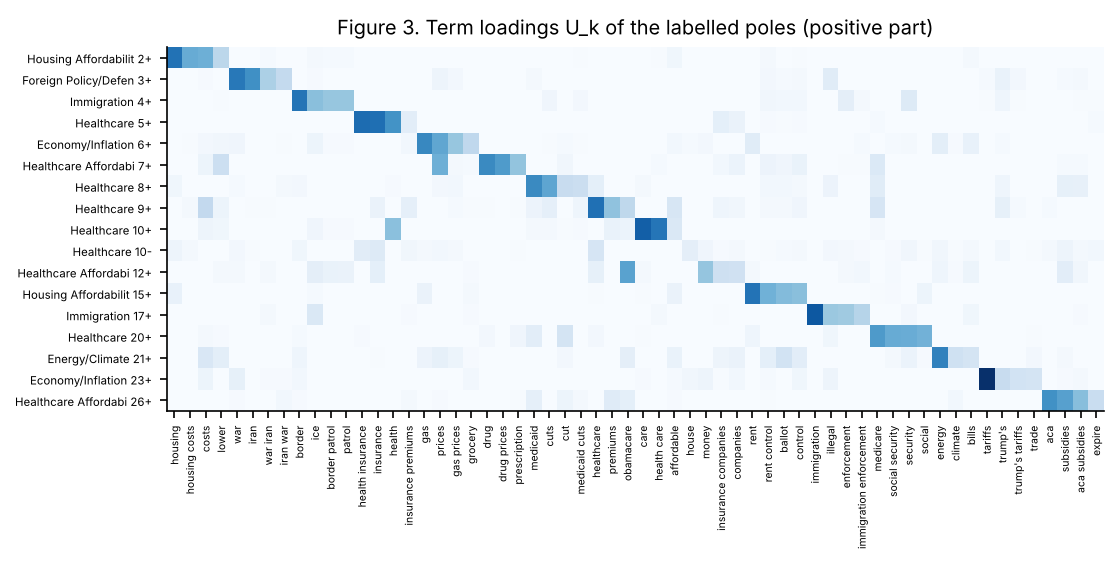

In [4]:
display(Markdown(tg.to_markdown(R.tables['table1a_svd_topics'], 2)))
display(Image('outputs/figures/fig2_spectrum_stability.png'))
display(Image('outputs/figures/fig3_loading_heatmap.png'))

In [5]:
R.model_comparison

,method,components,umass_coherence,topic_diversity,share_labelled,issues_found
0,NMF,12,-1.771939,0.891667,0.692228,6
1,LDA,12,-1.724304,0.658333,0.685523,5


## 3. Salience and topic-conditioned sentiment (Table 1B)

| Issue | Docs | Salience | S mean | S sd | % Pos | % Neg | % Anxiety | % Anger | % Optimism | % Re-signed | Coverage | Used |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Economy/Inflation | 416 | 0.17 | -0.40 | 0.25 | 25.00 | 71.88 | 14.90 | 6.01 | 14.66 | 13.46 | 0.98 | yes |
| Housing Affordability | 447 | 0.03 | 0.01 | 0.27 | 47.65 | 42.06 | 13.87 | 3.36 | 15.88 | 9.40 | 0.98 | yes |
| Healthcare Affordability | 401 | 0.07 | -0.17 | 0.26 | 41.90 | 50.37 | 6.48 | 4.24 | 11.97 | 12.97 | 0.99 | yes |
| Healthcare | 1,076 | 0.27 | -0.04 | 0.21 | 45.35 | 51.39 | 11.43 | 6.88 | 11.15 | 7.62 | 0.99 | yes |
| Energy/Climate | 160 | 0.08 | 0.24 | 0.23 | 72.50 | 26.25 | 13.75 | 3.12 | 31.87 | 5.00 | 0.96 | yes |
| Immigration | 480 | 0.25 | -0.01 | 0.29 | 44.79 | 46.88 | 9.17 | 7.50 | 13.12 | 1.67 | 0.98 | yes |
| Foreign Policy/Defense | 269 | 0.12 | -0.77 | 0.15 | 8.92 | 89.59 | 25.28 | 8.18 | 21.93 | 0.37 | 0.88 | yes |
| Technology/AI | 0 | 0.00 | – | – | – | – | – | – | – | – | 0.00 | no (too sparse) |

,coverage,used,unit_mass
Economy/Inflation,0.980645,True,0.034565
Housing Affordability,0.980645,True,0.051329
Healthcare Affordability,0.993548,True,0.059195
Healthcare,0.993548,True,0.049850
Energy/Climate,0.961290,True,0.019849
Immigration,0.980645,True,0.040527
Foreign Policy/Defense,0.877419,True,0.029625
Technology/AI,0.000000,False,NaN


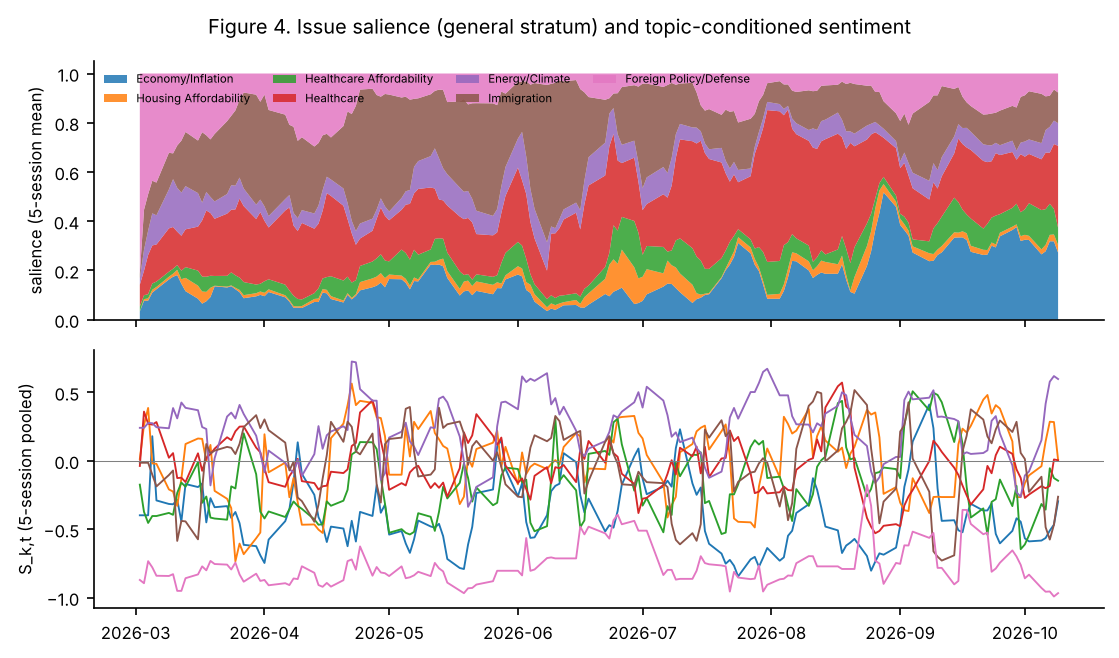

In [6]:
display(Markdown(tg.to_markdown(R.tables['table1b_issue_sentiment'], 2)))
display(R.signal_coverage)
display(Image('outputs/figures/fig4_salience_sentiment.png'))

## 4. Stationarity and lag order

In [7]:
display(R.adf.round(3))
R.lag_table.round(3)

,adf_stat,p_value,stationary
series,,,
S_Economy/Inflation,-3.600,0.006,True
S_Housing Affordability,-3.789,0.003,True
S_Healthcare Affordability,-3.614,0.005,True
S_Healthcare,-5.352,0.000,True
S_Energy/Climate,-3.685,0.004,True
S_Immigration,-4.242,0.001,True
S_Foreign Policy/Defense,-4.901,0.000,True
dProb_House,-4.034,0.001,True
dProb_Senate,-10.568,0.000,True


,aic,bic,hqic,fpe
lags,,,,
0,-50.630,-50.429,-50.548,0.0
1,-56.382,-54.165,-55.481,0.0
2,-56.124,-51.890,-54.404,0.0
3,-56.015,-49.765,-53.475,0.0
4,-55.701,-47.435,-52.343,0.0
5,-55.445,-45.163,-51.268,0.0


## 5. Stage 1: sentiment → prediction markets (Table 2)

In [8]:
display(Markdown(tg.to_markdown(R.tables['table2_granger_stage1'])))
R.stage1_salience.sort_values('p_value').head(8)

| Issue | Contract | Lags | N | F | p | q (BH) | Sig. | Σγ | ΔR² | p (3d) | p (rev) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Economy/Inflation | House | 1 | 153 | 0.685 | 0.409 | 0.741 |  | -0.002 | 0.003 | 0.428 | 0.069 |
| Economy/Inflation | Senate | 1 | 153 | 0.050 | 0.823 | 0.983 |  | -0.000 | 0.000 | 0.437 | 0.534 |
| Economy/Inflation | Sweep | 1 | 153 | 0.063 | 0.801 | 0.983 |  | -0.001 | 0.000 | 0.407 | 0.154 |
| Energy/Climate | House | 1 | 153 | 0.006 | 0.940 | 0.983 |  | -0.000 | 0.000 | 0.169 | 0.064 |
| Energy/Climate | Senate | 1 | 153 | 0.489 | 0.485 | 0.784 |  | -0.002 | 0.002 | 0.202 | 0.352 |
| Energy/Climate | Sweep | 1 | 153 | 0.876 | 0.351 | 0.741 |  | -0.002 | 0.003 | 0.334 | 0.242 |
| Foreign Policy/Defense | House | 1 | 153 | 3.802 | 0.053 | 0.557 | * | 0.008 | 0.028 | 0.265 | 0.989 |
| Foreign Policy/Defense | Senate | 1 | 153 | 2.496 | 0.116 | 0.625 |  | 0.008 | 0.014 | 0.957 | 0.765 |
| Foreign Policy/Defense | Sweep | 1 | 153 | 0.260 | 0.611 | 0.917 |  | 0.002 | 0.001 | 0.724 | 0.927 |
| Healthcare | House | 3 | 151 | 1.025 | 0.384 | 0.741 |  | -0.001 | 0.011 | 0.762 | 0.481 |
| Healthcare | Senate | 1 | 153 | 2.234 | 0.137 | 0.625 |  | -0.005 | 0.011 | 0.033 | 0.605 |
| Healthcare | Sweep | 3 | 151 | 2.832 | 0.041 | 0.557 | ** | -0.000 | 0.036 | 0.178 | 0.105 |
| Healthcare Affordability | House | 1 | 153 | 0.994 | 0.320 | 0.741 |  | 0.003 | 0.011 | 0.452 | 0.990 |
| Healthcare Affordability | Senate | 1 | 153 | 0.006 | 0.939 | 0.983 |  | -0.000 | 0.000 | 0.883 | 0.233 |
| Healthcare Affordability | Sweep | 1 | 153 | 0.004 | 0.947 | 0.983 |  | 0.000 | 0.000 | 0.798 | 0.485 |
| Housing Affordability | House | 1 | 153 | 0.000 | 0.983 | 0.983 |  | -0.000 | 0.000 | 0.772 | 0.716 |
| Housing Affordability | Senate | 1 | 153 | 1.508 | 0.221 | 0.741 |  | -0.004 | 0.011 | 0.060 | 0.688 |
| Housing Affordability | Sweep | 1 | 153 | 0.763 | 0.384 | 0.741 |  | -0.002 | 0.005 | 0.546 | 0.096 |
| Immigration | House | 1 | 153 | 2.107 | 0.149 | 0.625 |  | 0.002 | 0.007 | 0.157 | 0.664 |
| Immigration | Senate | 1 | 153 | 0.645 | 0.423 | 0.741 |  | -0.003 | 0.006 | 0.443 | 0.308 |
| Immigration | Sweep | 1 | 153 | 0.158 | 0.691 | 0.968 |  | -0.001 | 0.001 | 0.676 | 0.895 |

,cause,effect,lags,F,p_value,df_num,df_den,nobs,sum_gamma,r2_gain,cov,q_value
5,sal_Immigration,dProb_House,2,2.824059,0.062657,2,144,152,-0.008111,0.065762,HC1,0.949238
20,sal_Foreign Policy/Defense,dProb_Sweep,2,2.389644,0.095289,2,144,152,0.009247,0.027593,HC1,0.949238
1,sal_Housing Affordability,dProb_House,1,1.555880,0.214253,1,147,153,0.019746,0.006638,HC1,0.949238
14,sal_Economy/Inflation,dProb_Sweep,2,1.511599,0.224036,2,144,152,0.009530,0.015731,HC1,0.949238
12,sal_Immigration,dProb_Senate,2,1.488328,0.229202,2,144,152,-0.006098,0.014463,HC1,0.949238
7,sal_Economy/Inflation,dProb_Senate,2,1.291741,0.277957,2,144,152,0.008350,0.013096,HC1,0.949238
4,sal_Energy/Climate,dProb_House,1,0.750265,0.387804,1,147,153,0.011234,0.003585,HC1,0.949238
6,sal_Foreign Policy/Defense,dProb_House,1,0.612388,0.435149,1,147,153,0.003382,0.002031,HC1,0.949238


## 6. Covariance SVD: political alpha factors

singular values [0.783 0.702 0.484] perm p [0.735 0.24  0.539] trained to 2026-07-14


,F1,F2,F3
Economy/Inflation,-0.03,0.35,-0.04
Housing Affordability,-0.13,-0.23,-0.48
Healthcare Affordability,-0.25,-0.35,0.68
Healthcare,0.45,-0.30,0.42
Energy/Climate,-0.66,0.40,0.24
Immigration,-0.24,-0.59,-0.27
Foreign Policy/Defense,-0.47,-0.31,-0.03


,factor,oos_days,oos_corr,oos_t,sign_hit_rate,targets_right_sign
0,F1,62,-0.285,-2.306,0.403,0.318
1,F2,62,0.031,0.240,0.484,0.727
2,F3,62,-0.076,-0.588,0.452,0.545


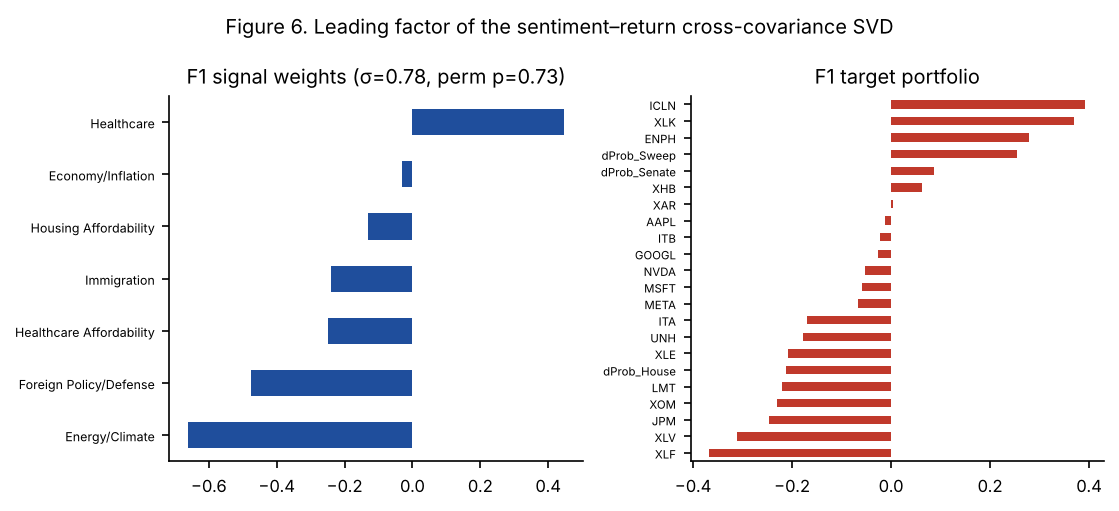

In [9]:
cs = R.cov_svd
print('singular values', cs.S.round(3), 'perm p', cs.p_values.round(3), 'trained to', cs.train_end.date())
display(cs.U.round(2))
display(R.factor_oos.round(3))
display(Image('outputs/figures/fig6_covariance_svd.png'))

## 7. Stage 2: prediction markets → midterm basket (Table 3) and robustness

| Asset | Contract | Ret F | Ret p | Ret q | Ret Σγ | Vol F | Vol p | Vol q | β OLS | β RS | RS 95% CI | VarH/VarL | Relevance p |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| XLE | House | 0.633 | 0.428 | 0.735 | -0.168 | 0.027 | 0.869 | 0.952 | 0.287 | 3.993 | [-14.19, 10.85] | 0.884 | 0.629 |
| XLE | Senate | 2.458 | 0.119 | 0.489 | -0.275 | 4.307 | 0.040 | 0.446 | 0.093 | -1.367 | [-15.73, 13.05] | 1.677 | 0.034 |
| XLE | Sweep | 0.998 | 0.319 | 0.667 | -0.178 | 0.091 | 0.763 | 0.882 | -0.099 | 0.092 | [-5.61, 7.91] | 2.017 | 0.006 |
| ICLN | House | 14.236 | 0.000 | 0.013 | -0.477 | 4.987 | 0.027 | 0.385 | -0.300 | -3.062 | [-12.40, 12.41] | 0.884 | 0.629 |
| ICLN | Senate | 0.045 | 0.832 | 0.949 | 0.027 | 0.020 | 0.888 | 0.955 | 0.146 | 0.360 | [-7.22, 6.80] | 1.677 | 0.034 |
| ICLN | Sweep | 2.084 | 0.151 | 0.494 | 0.185 | 0.419 | 0.659 | 0.841 | 0.075 | -0.146 | [-8.28, 5.16] | 2.017 | 0.006 |
| XLV | House | 1.903 | 0.170 | 0.509 | 0.162 | 0.428 | 0.514 | 0.841 | 0.197 | 2.423 | [-8.90, 9.85] | 0.884 | 0.629 |
| XLV | Senate | 0.063 | 0.802 | 0.949 | -0.021 | 0.805 | 0.371 | 0.784 | -0.053 | -0.696 | [-5.69, 4.44] | 1.677 | 0.034 |
| XLV | Sweep | 5.924 | 0.016 | 0.115 | -0.242 | 0.086 | 0.770 | 0.882 | -0.147 | -0.384 | [-4.32, 3.24] | 2.017 | 0.006 |
| XLF | House | 0.020 | 0.887 | 0.969 | -0.014 | 0.660 | 0.418 | 0.802 | 0.181 | -0.352 | [-5.97, 4.93] | 0.884 | 0.629 |
| XLF | Senate | 2.457 | 0.119 | 0.489 | -0.097 | 0.302 | 0.583 | 0.841 | -0.075 | 0.248 | [-3.04, 3.72] | 1.677 | 0.034 |
| XLF | Sweep | 8.997 | 0.003 | 0.045 | -0.222 | 4.016 | 0.047 | 0.446 | -0.187 | 0.142 | [-2.30, 3.04] | 2.017 | 0.006 |
| XAR | House | 0.539 | 0.464 | 0.735 | -0.106 | 0.224 | 0.637 | 0.841 | -0.017 | 2.573 | [-10.22, 13.04] | 0.884 | 0.629 |
| XAR | Senate | 0.132 | 0.717 | 0.949 | 0.039 | 0.200 | 0.655 | 0.841 | 0.078 | -0.368 | [-4.81, 4.73] | 1.677 | 0.034 |
| XAR | Sweep | 0.006 | 0.937 | 0.981 | 0.009 | 2.106 | 0.149 | 0.564 | 0.111 | -0.005 | [-4.37, 4.94] | 2.017 | 0.006 |
| ITA | House | 0.498 | 0.482 | 0.742 | -0.080 | 0.126 | 0.723 | 0.877 | 0.043 | 1.269 | [-5.52, 11.77] | 0.884 | 0.629 |
| ITA | Senate | 0.042 | 0.837 | 0.949 | -0.019 | 0.189 | 0.664 | 0.841 | 0.018 | -0.049 | [-3.75, 3.95] | 1.677 | 0.034 |
| ITA | Sweep | 0.965 | 0.328 | 0.667 | -0.098 | 1.356 | 0.246 | 0.668 | 0.030 | 0.168 | [-4.22, 4.98] | 2.017 | 0.006 |
| XLK | House | 0.868 | 0.353 | 0.673 | -0.105 | 0.426 | 0.654 | 0.841 | -0.196 | -1.848 | [-5.57, 6.57] | 0.884 | 0.629 |
| XLK | Senate | 0.042 | 0.837 | 0.949 | 0.018 | 2.249 | 0.109 | 0.479 | 0.072 | -0.285 | [-5.52, 5.87] | 1.677 | 0.034 |
| XLK | Sweep | 9.772 | 0.002 | 0.041 | 0.289 | 2.587 | 0.079 | 0.449 | 0.162 | -0.167 | [-4.66, 3.29] | 2.017 | 0.006 |
| ITB | House | 0.080 | 0.778 | 0.949 | 0.056 | 0.378 | 0.540 | 0.841 | 0.141 | -4.186 | [-9.57, 17.64] | 0.884 | 0.629 |
| ITB | Senate | 0.015 | 0.901 | 0.969 | -0.015 | 0.003 | 0.954 | 0.975 | -0.111 | 0.987 | [-11.92, 15.13] | 1.677 | 0.034 |
| ITB | Sweep | 0.004 | 0.947 | 0.981 | -0.009 | 0.527 | 0.469 | 0.835 | 0.025 | 0.300 | [-3.42, 6.76] | 2.017 | 0.006 |
| XHB | House | 0.074 | 0.787 | 0.949 | -0.046 | 0.900 | 0.344 | 0.762 | 0.121 | -3.187 | [-7.55, 14.22] | 0.884 | 0.629 |
| XHB | Senate | 0.002 | 0.967 | 0.984 | -0.005 | 0.132 | 0.717 | 0.877 | -0.115 | 0.805 | [-9.75, 14.34] | 1.677 | 0.034 |
| XHB | Sweep | 0.036 | 0.849 | 0.949 | -0.024 | 1.031 | 0.312 | 0.762 | 0.042 | 0.058 | [-2.66, 4.40] | 2.017 | 0.006 |
| ENPH | House | 2.151 | 0.145 | 0.494 | -0.692 | 1.366 | 0.244 | 0.668 | -0.645 | -1.156 | [-24.34, 23.61] | 0.884 | 0.629 |
| ENPH | Senate | 0.110 | 0.740 | 0.949 | -0.107 | 0.285 | 0.594 | 0.841 | 0.036 | 0.407 | [-12.99, 15.66] | 1.677 | 0.034 |
| ENPH | Sweep | 2.334 | 0.129 | 0.489 | 0.588 | 0.949 | 0.390 | 0.793 | -0.328 | -0.304 | [-9.11, 8.90] | 2.017 | 0.006 |
| XOM | House | 0.796 | 0.374 | 0.687 | -0.223 | 0.204 | 0.652 | 0.841 | 0.432 | 5.266 | [-18.92, 15.78] | 0.884 | 0.629 |
| XOM | Senate | 2.380 | 0.125 | 0.489 | -0.319 | 3.453 | 0.065 | 0.449 | 0.113 | -1.348 | [-14.76, 13.09] | 1.677 | 0.034 |
| XOM | Sweep | 0.969 | 0.327 | 0.667 | -0.203 | 0.234 | 0.629 | 0.841 | -0.130 | -0.287 | [-7.42, 6.87] | 2.017 | 0.006 |
| UNH | House | 1.214 | 0.272 | 0.621 | 0.340 | 0.003 | 0.958 | 0.975 | -0.097 | 3.288 | [-14.77, 9.57] | 0.884 | 0.629 |
| UNH | Senate | 0.541 | 0.463 | 0.735 | -0.122 | 0.965 | 0.328 | 0.762 | -0.053 | -0.907 | [-7.78, 7.10] | 1.677 | 0.034 |
| UNH | Sweep | 10.083 | 0.002 | 0.041 | -0.456 | 2.962 | 0.087 | 0.453 | -0.438 | -0.402 | [-3.74, 3.86] | 2.017 | 0.006 |
| JPM | House | 0.168 | 0.683 | 0.949 | -0.071 | 3.241 | 0.074 | 0.449 | 0.305 | 0.090 | [-6.85, 5.86] | 0.884 | 0.629 |
| JPM | Senate | 1.742 | 0.189 | 0.538 | -0.126 | 0.286 | 0.594 | 0.841 | -0.118 | -0.027 | [-3.10, 4.58] | 1.677 | 0.034 |
| JPM | Sweep | 4.829 | 0.030 | 0.187 | -0.267 | 6.833 | 0.010 | 0.385 | -0.191 | -0.211 | [-4.00, 4.27] | 2.017 | 0.006 |
| LMT | House | 0.368 | 0.545 | 0.796 | -0.118 | 0.888 | 0.348 | 0.762 | 0.228 | 13.212 | [-41.88, 43.12] | 0.884 | 0.629 |
| LMT | Senate | 0.549 | 0.460 | 0.735 | -0.106 | 0.000 | 0.996 | 0.996 | 0.086 | -0.229 | [-8.12, 6.13] | 1.677 | 0.034 |
| LMT | Sweep | 0.675 | 0.413 | 0.735 | -0.128 | 0.003 | 0.958 | 0.975 | 0.037 | 0.699 | [-5.50, 9.87] | 2.017 | 0.006 |
| NVDA | House | 0.000 | 0.998 | 0.998 | 0.000 | 2.010 | 0.158 | 0.564 | 0.095 | 1.438 | [-8.43, 9.36] | 0.884 | 0.629 |
| NVDA | Senate | 7.417 | 0.007 | 0.059 | 0.303 | 0.083 | 0.773 | 0.882 | 0.099 | -0.062 | [-5.68, 4.49] | 1.677 | 0.034 |
| NVDA | Sweep | 7.750 | 0.006 | 0.058 | 0.379 | 2.652 | 0.106 | 0.479 | 0.414 | -0.129 | [-10.07, 6.96] | 2.017 | 0.006 |
| MSFT | House | 1.670 | 0.198 | 0.538 | 0.231 | 0.593 | 0.442 | 0.813 | 0.278 | 4.005 | [-13.31, 11.42] | 0.884 | 0.629 |
| MSFT | Senate | 1.409 | 0.237 | 0.588 | -0.161 | 1.598 | 0.208 | 0.668 | 0.241 | 0.783 | [-7.35, 10.87] | 1.677 | 0.034 |
| MSFT | Sweep | 2.033 | 0.156 | 0.494 | -0.219 | 2.223 | 0.138 | 0.562 | -0.070 | 1.459 | [-11.71, 18.30] | 2.017 | 0.006 |
| GOOGL | House | 0.214 | 0.644 | 0.918 | 0.139 | 0.067 | 0.796 | 0.890 | -0.391 | -1.889 | [-14.65, 11.25] | 0.884 | 0.629 |
| GOOGL | Senate | 1.439 | 0.232 | 0.588 | 0.115 | 0.649 | 0.422 | 0.802 | 0.072 | 0.343 | [-10.15, 11.84] | 1.677 | 0.034 |
| GOOGL | Sweep | 1.254 | 0.265 | 0.621 | -0.160 | 1.124 | 0.291 | 0.754 | 0.081 | 0.752 | [-10.58, 15.64] | 2.017 | 0.006 |
| META | House | 4.021 | 0.047 | 0.267 | 0.631 | 3.386 | 0.068 | 0.449 | 0.043 | 4.428 | [-14.51, 11.10] | 0.884 | 0.629 |
| META | Senate | 8.338 | 0.004 | 0.051 | 0.534 | 5.396 | 0.022 | 0.385 | -0.151 | -0.844 | [-12.85, 10.15] | 1.677 | 0.034 |
| META | Sweep | 3.350 | 0.069 | 0.359 | 0.408 | 1.566 | 0.213 | 0.668 | -0.181 | -0.727 | [-8.62, 7.20] | 2.017 | 0.006 |
| AAPL | House | 0.452 | 0.502 | 0.754 | -0.100 | 0.353 | 0.553 | 0.841 | -0.059 | -0.646 | [-5.71, 8.53] | 0.884 | 0.629 |
| AAPL | Senate | 0.863 | 0.354 | 0.673 | -0.101 | 5.388 | 0.022 | 0.385 | -0.226 | 0.469 | [-4.24, 7.54] | 1.677 | 0.034 |
| AAPL | Sweep | 0.070 | 0.792 | 0.949 | 0.040 | 1.356 | 0.246 | 0.668 | -0.490 | -0.071 | [-6.31, 4.25] | 2.017 | 0.006 |

,stage,cause,effect,sum_gamma,p,p_HAC,p_no_extremes,p_excl_dates,p_1st_half,gamma_1st_half,p_2nd_half,gamma_2nd_half,p_placebo,robust
0,2 ret,dProb_House,ICLN,-0.4768,0.0002,0.0004,0.1489,0.0000,0.0008,-0.4633,0.4613,-0.1926,0.9770,False
1,2 ret,dProb_Sweep,XLF,-0.2218,0.0032,0.0022,0.0399,0.0046,0.0623,-0.2340,0.0393,-0.2058,0.7852,True
2,2 ret,dProb_Sweep,XLK,0.2894,0.0021,0.0025,0.0063,0.0033,0.1294,0.2491,0.0029,0.3830,0.1901,True
3,2 ret,dProb_Sweep,UNH,-0.4555,0.0018,0.0016,0.0042,0.0027,0.0154,-0.6419,0.0642,-0.2619,0.4651,True
4,2 ret,dProb_Senate,NVDA,0.3026,0.0072,0.0080,0.1242,0.0018,0.7628,0.0723,0.0017,0.4606,0.2900,False
5,2 ret,dProb_Sweep,NVDA,0.3786,0.0061,0.0063,0.0509,0.0086,0.4053,0.1984,0.0031,0.5034,0.1849,True
6,2 ret,dProb_Senate,META,0.5335,0.0045,0.0027,0.0509,0.0033,0.3828,0.2699,0.0188,0.5865,0.9525,True


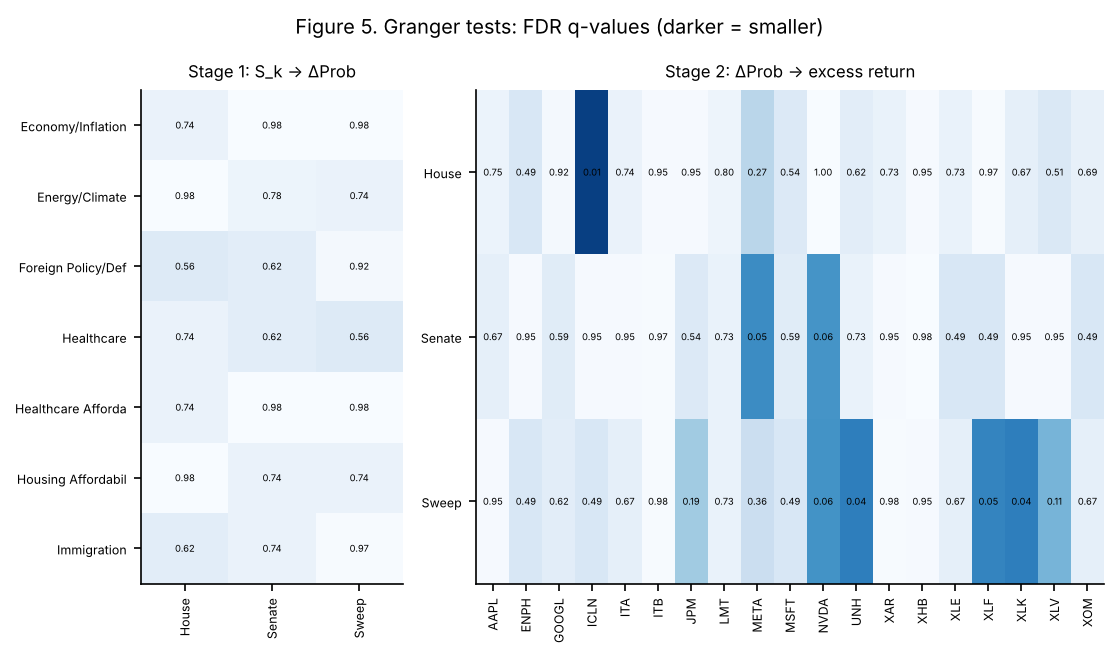

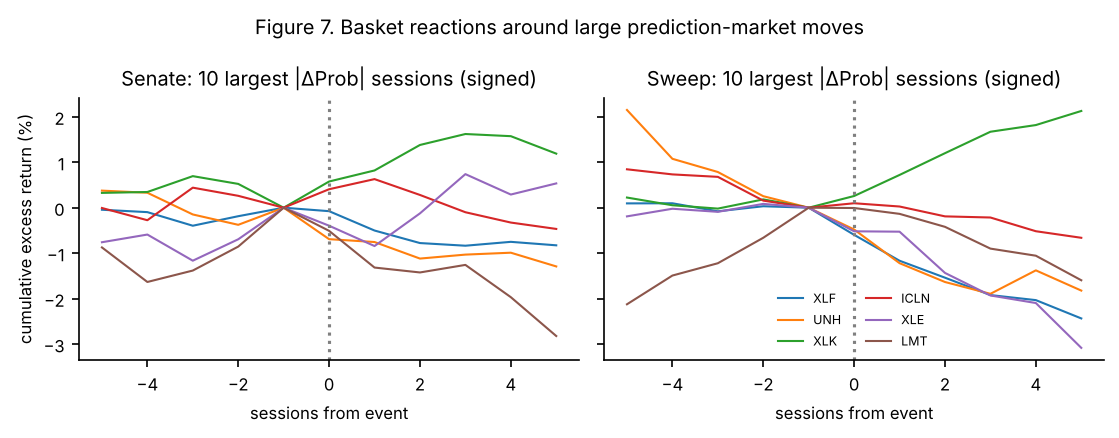

In [10]:
display(Markdown(tg.to_markdown(R.tables['table3_basket_reactivity'])))
display(R.robustness.round(4))
display(Image('outputs/figures/fig5_granger_q.png'))
display(Image('outputs/figures/fig7_event_study.png'))

In [11]:
R.sentiment_to_asset.sort_values('p_value').round(4)

,cause,effect,lags,F,p_value,df_num,df_den,nobs,sum_gamma,r2_gain,cov,q_value
3,S_Energy/Climate,XOM,1,3.8134,0.0527,1,147,153,0.0152,0.0226,HC1,0.4221
0,S_Energy/Climate,ICLN,1,3.7019,0.0563,1,147,153,-0.0112,0.0259,HC1,0.4221
2,S_Energy/Climate,XLE,1,2.4503,0.1197,1,147,153,0.0101,0.0136,HC1,0.5112
4,S_Healthcare,XLV,1,1.9652,0.1631,1,147,153,0.0077,0.0159,HC1,0.5112
7,S_Healthcare Affordability,UNH,1,1.8981,0.1704,1,147,153,-0.0079,0.0119,HC1,0.5112
1,S_Energy/Climate,ENPH,1,1.5467,0.2156,1,147,153,-0.0237,0.0138,HC1,0.5162
6,S_Healthcare Affordability,XLV,1,1.3865,0.2409,1,147,153,0.0053,0.0117,HC1,0.5162
5,S_Healthcare,UNH,1,0.4726,0.4929,1,147,153,-0.0047,0.0027,HC1,0.7695
13,S_Foreign Policy/Defense,ITA,1,0.4637,0.4970,1,147,153,0.0045,0.0028,HC1,0.7695
9,S_Economy/Inflation,JPM,1,0.3392,0.5612,1,147,153,0.0022,0.0020,HC1,0.7695


## 8. Rigobon–Sack heteroskedasticity check

In [12]:
rs = R.rigobon_sack
display(rs.groupby('contract')[['var_ratio_x', 'var_ratio_p', 'var_ratio_y']].median().round(3))
rs[['asset', 'contract', 'beta_ols', 'beta_rs', 'ci_low', 'ci_high']].round(3)

,var_ratio_x,var_ratio_p,var_ratio_y
contract,,,
House,0.884,0.629,0.82
Senate,1.677,0.034,0.82
Sweep,2.017,0.006,0.82


,asset,contract,beta_ols,beta_rs,ci_low,ci_high
0,XLE,House,0.287,3.993,-14.189,10.847
1,ICLN,House,-0.300,-3.062,-12.396,12.415
2,XLV,House,0.197,2.423,-8.903,9.848
3,XLF,House,0.181,-0.352,-5.971,4.926
4,XAR,House,-0.017,2.573,-10.218,13.045
5,ITA,House,0.043,1.269,-5.521,11.772
6,XLK,House,-0.196,-1.848,-5.575,6.565
7,ITB,House,0.141,-4.186,-9.569,17.644
8,XHB,House,0.121,-3.187,-7.551,14.219
9,ENPH,House,-0.645,-1.156,-24.337,23.608
